In [2]:
import torch

# GPU 사용 가능 여부 확인
print("CUDA available:", torch.cuda.is_available())

# 사용 가능한 GPU 개수
print("Number of GPUs:", torch.cuda.device_count())

# 현재 기본 GPU 이름
if torch.cuda.is_available():
    print("Current GPU:", torch.cuda.get_device_name(torch.cuda.current_device()))


CUDA available: True
Number of GPUs: 1
Current GPU: NVIDIA GeForce RTX 5060 Ti


In [28]:
import torch  
print(torch.cuda.is_available())  
print(torch.cuda.get_device_name(0))  

True
NVIDIA GeForce RTX 5060 Ti


In [2]:
import torch
print(torch.version.cuda)       # PyTorch에서 인식하는 CUDA 버전
print(torch.cuda.is_available()) # True 여야 정상


12.8
True


In [30]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
x = torch.randn(32, 10, device=device)
y = torch.randn(32, 1, device=device)
model = torch.nn.Linear(10, 1).to(device)
output = model(x)
print(output[:5])


tensor([[-0.0073],
        [ 0.0674],
        [-0.6620],
        [ 1.0873],
        [-0.0945]], device='cuda:0', grad_fn=<SliceBackward0>)


In [31]:
import pydicom

# 파일 경로
file_path = r"C:\Users\chwo6\OneDrive\바탕 화면\cuda_test\0002.DCM"

# DICOM 파일 읽기
ds = pydicom.dcmread(file_path)

# 기본 정보 출력
print(ds)
print("Patient Name:", ds.get("PatientName", "Unknown"))
print("Modality:", ds.get("Modality", "Unknown"))
print("Image Shape:", ds.pixel_array.shape if "PixelData" in ds else "No image data")


Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 150
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: X-Ray Angiographic Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.3.12.2.1107.5.4.3.321890.19960124.162922.29
(0002,0010) Transfer Syntax UID                 UI: JPEG Baseline (Process 1)
(0002,0012) Implementation Class UID            UI: 999.999
-------------------------------------------------
(0008,0008) Image Type                          CS: ['DERIVED', 'PRIMARY', 'SINGLE PLANE', 'SINGLE A']
(0008,0016) SOP Class UID                       UI: X-Ray Angiographic Image Storage
(0008,0018) SOP Instance UID                    UI: 1.3.12.2.1107.5.4.3.321890.19960124.162922.29
(0008,0020) Study Date                          DA: '19941013'
(0008,0030) Study Time                          TM: '141917'
(0008,0050) Accession Number                    S

In [33]:
ds

Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 150
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: X-Ray Angiographic Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.3.12.2.1107.5.4.3.321890.19960124.162922.29
(0002,0010) Transfer Syntax UID                 UI: JPEG Baseline (Process 1)
(0002,0012) Implementation Class UID            UI: 999.999
-------------------------------------------------
(0008,0008) Image Type                          CS: ['DERIVED', 'PRIMARY', 'SINGLE PLANE', 'SINGLE A']
(0008,0016) SOP Class UID                       UI: X-Ray Angiographic Image Storage
(0008,0018) SOP Instance UID                    UI: 1.3.12.2.1107.5.4.3.321890.19960124.162922.29
(0008,0020) Study Date                          DA: '19941013'
(0008,0030) Study Time                          TM: '141917'
(0008,0050) Accession Number                    S

Number of frames: 96


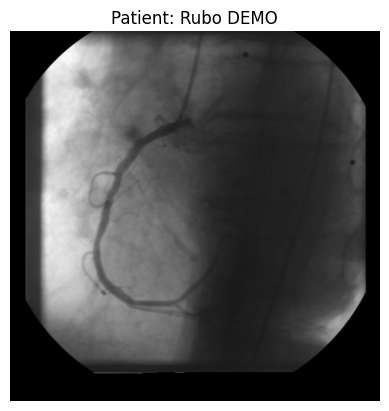

In [40]:
import pydicom
import matplotlib.pyplot as plt

file_path = r"C:\Users\chwo6\OneDrive\바탕 화면\cuda_test\0002.DCM"
ds = pydicom.dcmread(file_path)

# 멀티프레임 확인
num_frames = int(ds.get("NumberOfFrames", 1))
print(f"Number of frames: {num_frames}")

# 첫 번째 프레임 보기
if num_frames > 1:
    img = ds.pixel_array[34]  # 첫 번째 프레임
else:
    img = ds.pixel_array

plt.imshow(img, cmap='gray')
plt.axis('off')
plt.title(f"Patient: {ds.PatientName}")
plt.show()


In [ ]:
import os
from PIL import Image
import torch

from diffusers import QwenImageEditPipeline

pipeline = QwenImageEditPipeline.from_pretrained("Qwen/Qwen-Image-Edit")
print("pipeline loaded")
pipeline.to(torch.bfloat16)
pipeline.to("cuda")
pipeline.set_progress_bar_config(disable=None)
image = Image.open("./input.png").convert("RGB")
prompt = "Change the rabbit's color to purple, with a flash light background."
inputs = {
    "image": image,
    "prompt": prompt,
    "generator": torch.manual_seed(0),
    "true_cfg_scale": 4.0,
    "negative_prompt": " ",
    "num_inference_steps": 50,
}

with torch.inference_mode():
    output = pipeline(**inputs)
    output_image = output.images[0]
    output_image.save("output_image_edit.png")
    print("image saved at", os.path.abspath("output_image_edit.png"))


c:\Users\chwo6\.conda\envs\hw_cuda_12.8_torch_2.7.1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.
c:\Users\chwo6\.conda\envs\hw_cuda_12.8_torch_2.7.1\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\chwo6\.cache\huggingface\hub\models--Qwen--Qwen-Image-Edit. Caching files will still work but in a degraded version that might require more space on your disk

In [ ]:
pip install git+https://github.com/huggingface/diffusers

pip install transformers